In [5]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

**1. Import Libraries**

In [46]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression

from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score

**2. Load Dataset**

In [47]:
df=pd.read_csv('/kaggle/input/datasets/hassanzeeshan/energy-consumption/train_energy_data.csv')

In [48]:
df.head()

,Building Type,Square Footage,Number of Occupants,Appliances Used,Average Temperature,Day of Week,Energy Consumption
0,Residential,7063,76,10,29.84,Weekday,2713.95
1,Commercial,44372,66,45,16.72,Weekday,5744.99
2,Industrial,19255,37,17,14.30,Weekend,4101.24
3,Residential,13265,14,41,32.82,Weekday,3009.14
4,Commercial,13375,26,18,11.92,Weekday,3279.17


In [49]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 7 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Building Type        1000 non-null   object 
 1   Square Footage       1000 non-null   int64  
 2   Number of Occupants  1000 non-null   int64  
 3   Appliances Used      1000 non-null   int64  
 4   Average Temperature  1000 non-null   float64
 5   Day of Week          1000 non-null   object 
 6   Energy Consumption   1000 non-null   float64
dtypes: float64(2), int64(3), object(2)
memory usage: 54.8+ KB


In [50]:
df.describe()

,Square Footage,Number of Occupants,Appliances Used,Average Temperature,Energy Consumption
count,1000.000,1000.000000,1000.000000,1000.000000,1000.000000
mean,25462.388,48.372000,25.606000,22.611390,4166.252570
std,14294.554,29.061972,14.105166,7.139943,933.313064
min,560.000,1.000000,1.000000,10.050000,1683.950000
25%,13169.750,22.000000,13.000000,16.475000,3509.482500
50%,25477.000,47.000000,26.000000,22.815000,4175.730000
75%,37446.250,73.250000,38.000000,28.850000,4863.850000
max,49997.000,99.000000,49.000000,34.990000,6530.600000


In [51]:
df.isnull().sum()

Building Type          0
Square Footage         0
Number of Occupants    0
Appliances Used        0
Average Temperature    0
Day of Week            0
Energy Consumption     0
dtype: int64

In [52]:
df['Building Type'].value_counts()

Building Type
Residential    347
Commercial     336
Industrial     317
Name: count, dtype: int64

In [53]:
df['Day of Week'].value_counts()

Day of Week
Weekday    507
Weekend    493
Name: count, dtype: int64

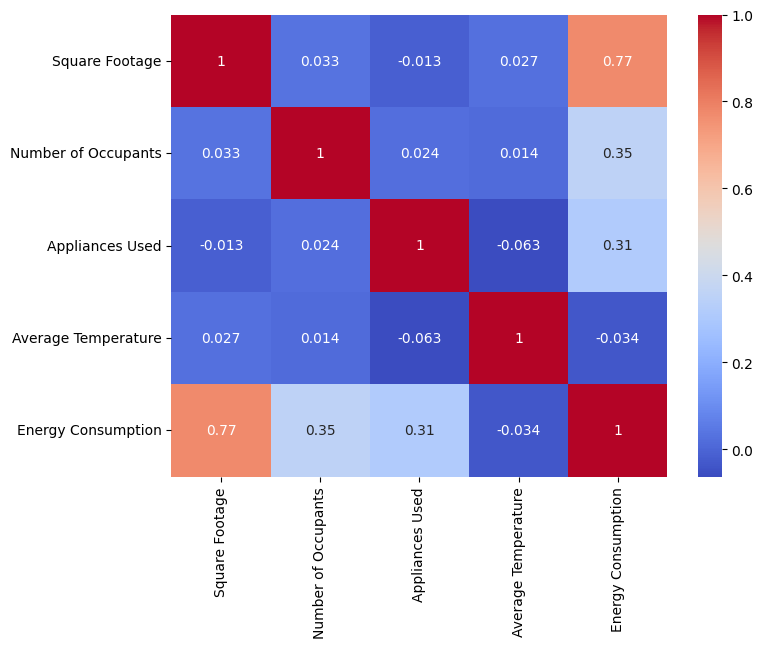

In [54]:
plt.figure(figsize=(8,6))
sns.heatmap(df.select_dtypes(include='number').corr(), annot=True, cmap='coolwarm')
plt.show()

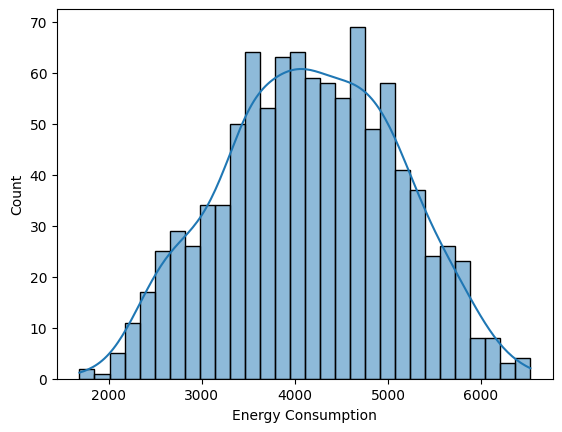

In [55]:
sns.histplot(df['Energy Consumption'], bins=30, kde=True)
plt.show()

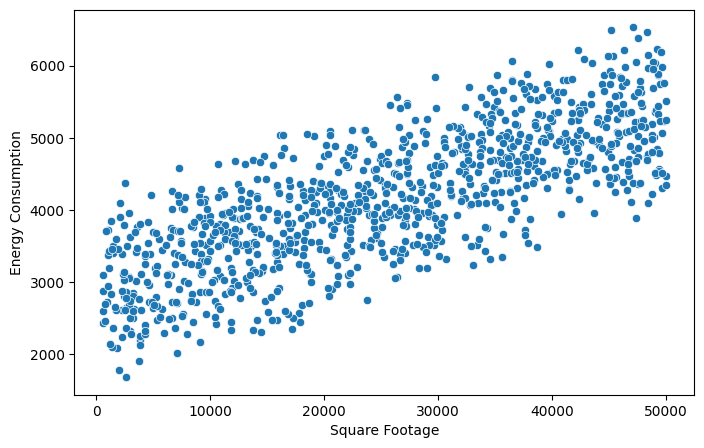

In [56]:
plt.figure(figsize=(8,5))
sns.scatterplot(x='Square Footage',
                y='Energy Consumption',
                data=df)

plt.show()

In [57]:
df = pd.get_dummies(df,
                    columns=['Building Type','Day of Week'],
                    drop_first=True)

In [58]:
df.head()

,Square Footage,Number of Occupants,Appliances Used,Average Temperature,Energy Consumption,Building Type_Industrial,Building Type_Residential,Day of Week_Weekend
0,7063,76,10,29.84,2713.95,False,True,False
1,44372,66,45,16.72,5744.99,False,False,False
2,19255,37,17,14.30,4101.24,True,False,True
3,13265,14,41,32.82,3009.14,False,True,False
4,13375,26,18,11.92,3279.17,False,False,False


In [59]:
X = df.drop('Energy Consumption', axis=1)

y = df['Energy Consumption']

In [60]:
X.head()

,Square Footage,Number of Occupants,Appliances Used,Average Temperature,Building Type_Industrial,Building Type_Residential,Day of Week_Weekend
0,7063,76,10,29.84,False,True,False
1,44372,66,45,16.72,False,False,False
2,19255,37,17,14.30,True,False,True
3,13265,14,41,32.82,False,True,False
4,13375,26,18,11.92,False,False,False


In [61]:
y.head()

0    2713.95
1    5744.99
2    4101.24
3    3009.14
4    3279.17
Name: Energy Consumption, dtype: float64

In [62]:
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.2,random_state=42)

In [63]:
X_train.head()

,Square Footage,Number of Occupants,Appliances Used,Average Temperature,Building Type_Industrial,Building Type_Residential,Day of Week_Weekend
29,27072,12,30,32.89,False,True,True
535,9874,5,19,20.65,False,False,False
695,22427,8,13,26.21,True,False,False
557,30129,29,33,23.73,False,True,True
836,16350,14,38,18.39,False,False,False


In [64]:
X_test.head()

,Square Footage,Number of Occupants,Appliances Used,Average Temperature,Building Type_Industrial,Building Type_Residential,Day of Week_Weekend
521,40192,23,23,30.00,False,False,True
737,8406,25,36,19.48,False,True,False
740,47719,92,7,32.82,True,False,True
660,37435,26,35,21.64,False,False,False
411,11331,47,43,21.10,False,False,True


In [65]:
LR= LinearRegression()

LR.fit(X_train, y_train)

LinearRegression()

In [66]:
y_pred = LR.predict(X_test)

In [67]:
y_pred

array([4549.59824445, 2842.90108278, 5781.84778821, 4773.55057726,
       3791.05021725, 2470.59933046, 5003.04942995, 3314.09985936,
       5147.10004702, 4298.89999809, 2998.54936661, 3915.70131235,
       5329.29807143, 4628.7993472 , 4682.44991532, 3658.95152071,
       3446.14840078, 5088.19896175, 4534.04894337, 5338.15050356,
       4073.00056184, 4978.70010629, 4354.2518773 , 3439.35138046,
       2512.09913165, 3699.84815236, 3796.70223862, 2683.75031552,
       5359.0998236 , 4802.20174747, 4828.19871143, 4315.7484956 ,
       3973.3492763 , 6053.70139847, 4023.40144696, 5543.65036909,
       3870.29835077, 3987.84972919, 3522.90023542, 4923.24943277,
       3708.10001114, 2728.65009927, 4302.79875471, 4860.79865699,
       5247.04989425, 4261.04969598, 3437.75052574, 4749.65080748,
       2260.79912769, 4847.0999624 , 4566.39919933, 5340.40016327,
       5842.69788868, 5744.85203571, 3930.1489088 , 4230.10230173,
       4496.55062461, 4318.60070537, 2514.39918706, 4534.85066

In [68]:
mae = mean_absolute_error(y_test, y_pred)

print("MAE:", mae)

MAE: 0.011412201063290012


In [69]:
mse = mean_squared_error(y_test, y_pred)

print("MSE:", mse)

MSE: 0.00018855085528760016


In [70]:
r2 = r2_score(y_test, y_pred)

print("R² Score:", r2)

R² Score: 0.9999999997684504


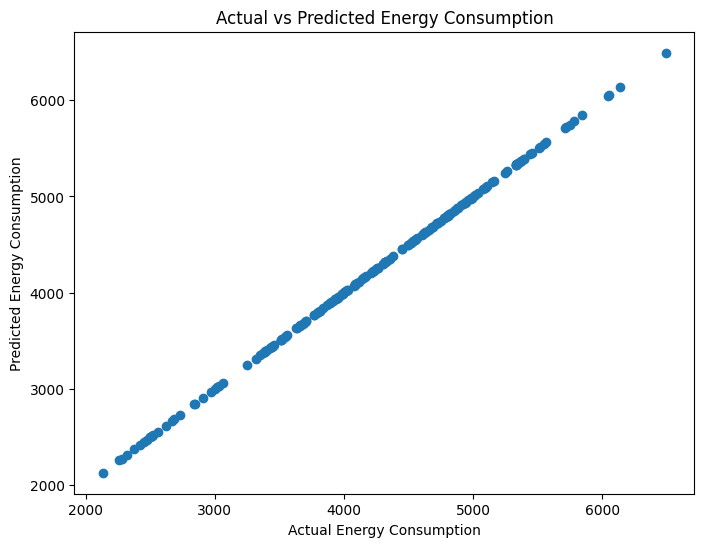

In [71]:
plt.figure(figsize=(8,6))

plt.scatter(y_test, y_pred)

plt.xlabel("Actual Energy Consumption")
plt.ylabel("Predicted Energy Consumption")
plt.title("Actual vs Predicted Energy Consumption")

plt.show()

In [72]:
coefficients = pd.DataFrame({
    'Feature': X.columns,
    'Coefficient': LR.coef_
})

print(coefficients)

                     Feature  Coefficient
0             Square Footage     0.050000
1        Number of Occupants    10.000003
2            Appliances Used    20.000015
3        Average Temperature    -5.000118
4   Building Type_Industrial   500.000028
5  Building Type_Residential  -500.000303
6        Day of Week_Weekend   -50.001103


In [74]:
test_df = pd.read_csv('/kaggle/input/datasets/hassanzeeshan/energy-consumption/test_energy_data.csv')

test_df.head()

,Building Type,Square Footage,Number of Occupants,Appliances Used,Average Temperature,Day of Week,Energy Consumption
0,Residential,24563,15,4,28.52,Weekday,2865.57
1,Commercial,27583,56,23,23.07,Weekend,4283.80
2,Commercial,45313,4,44,33.56,Weekday,5067.83
3,Residential,41625,84,17,27.39,Weekend,4624.30
4,Residential,36720,58,47,17.08,Weekday,4820.59


In [75]:
test_df = pd.get_dummies(test_df,
                         columns=['Building Type','Day of Week'],
                         drop_first=True)

In [76]:
test_df = test_df.reindex(columns=X.columns, fill_value=0)

In [78]:
predictions = LR.predict(test_df)

print(predictions[:10])

[2865.54919472 4283.79940731 5067.84908877 4624.2983363  4820.60111582
 5026.25054677 4404.54904558 2394.34990331 3969.09936227 5136.70214981]
